# Attention based multiple instance learning experiments

Aaron Emmanuel and George Mikhaiel

The notebook completes the supplied training scaffold and reviews the saved baseline and pooling-extension experiments.

## Experiment records
The default mode loads the validation-selected checkpoint and saved held-out results, without repeating test inference. Set `RUN_TRAINING=True` only for a fresh 30-epoch training experiment. The primary baseline records match the group report: C16 epoch 3, C17 epoch 21 and BRACS epoch 3. Earlier Mac C17 measurements remain in their original folder as an environment comparison, not as replacements for the group baseline. The encoder is fixed; no scheduler or warmup is implemented.

This notebook requires the supplied HDF5 features to inspect batches. The saved result tables and figures can also be read without executing the notebook. Large feature files and original slides are distributed separately; the README gives their sources. AI assistance supported implementation checks, analysis and editing; the authors are responsible for the submitted work.

## Learning objectives

After this project you should be able to explain and implement:

1. `Dataset` vs. `DataLoader`, batching, shuffling.
2. `nn.Module`, trainable parameters, and `forward()`.
3. A classification loss and optimizer.
4. The training sequence `zero_grad -> forward -> loss -> backward -> step`.
5. The difference between `model.train()` and `model.eval()`.

## Step 0. Download Pre-extracted WSI Features & Select the Project Directory
Download the required feature file(s) from Zenodo or Hugging Face:

https://zenodo.org/records/23130543

https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature


Place the HDF5 file under the path expected by your YAML configuration in the `config/`, or edit data_dir in the YAML file.


In [1]:
# Use the project interpreter selected in PyCharm / Jupyter.
# Install once if setting up a new environment:
# %pip install -r requirements.txt
import importlib.metadata as metadata
print({name: metadata.version(name) for name in ('torch', 'h5py', 'numpy', 'torchmetrics')})

{'torch': '2.8.0', 'h5py': '3.14.0', 'numpy': '2.0.2', 'torchmetrics': '1.8.2'}


In [2]:
import os, sys, copy, time, json, hashlib
import numpy as np
import pandas as pd
from IPython.display import display
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))



torch.set_num_threads(2)


Matplotlib is building the font cache; this may take a moment.


PyTorch: 2.8.0
CUDA available: False


If you are using Google Colab with Drive, mount Drive first and change `PROJECT_DIR`.

In [3]:
PROJECT_DIR = Path.cwd().resolve()
assert (PROJECT_DIR / 'model.py').exists(), 'Run this notebook from Project_A_Starter_Code.'
DATASET = 'C16'  # 'C16', 'C17', or 'BRACS'
RUN_TRAINING = False
RUN_HELD_OUT_TEST = False  # Fresh training: enable only after fixing the protocol.
RUN_WSI_FIGURES = False
RUNS = {'C16': 'C16_baseline_windows', 'C17': 'C17_baseline_windows',
        'BRACS': 'BRACS_baseline_windows'}
CONFIG_FILES = {'C16': 'camelyon16_medical_ssl_config.yml',
                'C17': 'camelyon17_medical_ssl_config.yml',
                'BRACS': 'bracs_medical_ssl_config.yml'}
CONFIG_PATH = PROJECT_DIR / 'config' / CONFIG_FILES[DATASET]
SAVED_RUN = PROJECT_DIR / 'results' / RUNS[DATASET]
TEST_RECORD = SAVED_RUN / 'heldout_test/metrics.json'
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
from wsi_visualization import visualize_wsi_attention
print('Project:', PROJECT_DIR)
print('Mode:', 'fresh training' if RUN_TRAINING else 'saved baseline results')

def load_saved_test(folder):
    record = json.loads((folder / 'heldout_test/metrics.json').read_text())
    predictions = pd.read_csv(folder / 'heldout_test/predictions.csv')
    saved_split = json.loads((folder / 'splits.json').read_text())
    assert predictions.slide_id.tolist() == saved_split['test']
    return dict(record, test=record['metrics'], test_slide_ids=predictions.slide_id.tolist())


Project: /Users/aaronemmanuel/Documents/Codex/2026-10-28/george-sent-the-ece1512-project-a/outputs/Project_A/Project_A_Starter_Code
Mode: saved baseline results


In [4]:
from dataloader import build_HDF5_feat_dataset, mil_collate_fn
from utils import load_config, seed_everything, infer_feature_dim, classification_metrics

conf = load_config(CONFIG_PATH)
seed_everything(int(conf.seed))
print(conf)

if os.path.exists(conf.data_dir):
    print('Feature file exists:', os.path.exists(conf.data_dir), conf.data_dir)
else:
    print('\nDownload the required feature file from: https://zenodo.org/records/23130543')
    print('Then update data_dir in:', CONFIG_PATH)
    

Struct(B=1, D_attn=128, D_feat=384, D_inner=256, data_dir='./feature/C16/patch_feats_pretrain_medical_ssl.h5', dataset='CAMELYON16', dataset_csv_dir='./dataset_csv', droprate=0.0, lr=0.0001, n_class=2, n_res=0, n_shot=0, n_worker=0, pin_memory=True, seed=42, train_epoch=30, val_fraction=0.1, warmup_epoch=3, wd=1e-05)
Feature file exists: True ./feature/C16/patch_feats_pretrain_medical_ssl.h5


# Step 1 - Dataset and DataLoader

`build_HDF5_feat_dataset` is provided. It creates train/validation/test `Dataset` objects without loading all slide features into memory at once.


Complete the three `DataLoader` definitions. Think about which split should be shuffled.

[Download WSI datasets](https://zenodo.org/records/23130543)

[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)


[PyTorch DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)


[PyTorch Datasets](https://docs.pytorch.org/vision/stable/datasets.html)


In [5]:
train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)
conf.D_feat = infer_feature_dim(train_data)
print('Split sizes: Train {}, Validation {}, Test {};'.format(len(train_data), len(val_data), len(test_data)))
print("Feature Shape: {};".format(tuple(train_data[1]['input'].shape)))
print("Label: {}; \nSlide ID: {}.".format(train_data[1]['label'], train_data[1]['slide_id']))

Split sizes: Train 242, Validation 27, Test 129;
Feature Shape: (4332, 384);
Label: 0; 
Slide ID: normal_028.


In [6]:
batch_size=conf.B
num_workers=int(conf.n_worker)
pin_memory=bool(conf.pin_memory) and torch.cuda.is_available()
collate_fn=mil_collate_fn
print("DataLoader args: Batch size {}; \n \
      # CPUs {};  \n \
      pin_memory {};  \n \
      collate_fn {}".format(batch_size, num_workers, pin_memory, collate_fn))


DataLoader args: Batch size 1; 
       # CPUs 0;  
       pin_memory False;  
       collate_fn <function mil_collate_fn at 0x14dbcec00>


In [7]:
# TODO 1 completed: shuffle training slides only; collate variable bags.
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
    num_workers=num_workers, pin_memory=pin_memory, collate_fn=collate_fn)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False,
    num_workers=num_workers, pin_memory=pin_memory, collate_fn=collate_fn)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False,
    num_workers=num_workers, pin_memory=pin_memory, collate_fn=collate_fn)


In [8]:
# Inspect one MIL batch.
batch = next(iter(train_loader))
print('input:', tuple(batch['input'].shape), batch['input'].dtype)
print('label:', tuple(batch['label'].shape), batch['label'].dtype)
print('slide IDs:', batch['slide_id'])

input: (1, 12367, 384) torch.float32
label: (1,) torch.int64
slide IDs: ['tumor_010']


**Questions for your report:**

- What is the difference between a `Dataset` and a `DataLoader`?
- Which Dataloader should use `shuffle=True`? Why?
- For a batch with input shape `[B, N, D]`, what do `B`, `N`, and `D` mean in this project?

**Discussion.** A Dataset returns one slide's features, label and identifier. A DataLoader batches Dataset samples and handles ordering, workers and collation. Only the training loader shuffles: random training order changes the gradient sequence, while stable validation/test ordering makes evaluation reproducible. In `[B,N,D]`, B is slides per batch, N is patches per slide (padded to the largest bag in a batch), and D is the 384-dimensional supplied feature vector. A Boolean mask excludes padded patches from attention. These experiments use B=1.


# Step 2 - Implement the ABMIL model

For each patch feature $h_i$, the gated attention score follows Ilse et al. (2018):

$$
a_i = w^T\left[\tanh(Vh_i) \odot \sigma(Uh_i)\right].
$$

The attention logits are normalized over instances:

$$
\alpha_i = \frac{\exp(a_i)}{\sum_j \exp(a_j)},
$$

and the slide representation is

$$
z = \sum_i \alpha_i h_i.
$$

You will implement the learnable layers and the key `forward()` operations.

[Custom nn Modules](https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_module.html)

[nn.Linear](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html)

[nn.modules.dropout](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Dropout.html)

[nn.ReLU](https://docs.pytorch.org/docs/2.14/generated/torch.nn.ReLU.html)

[torch.nn.functional.softmax (F.softmax)](https://docs.pytorch.org/docs/2.14/generated/torch.nn.functional.softmax.html)

[torch.bmm](https://docs.pytorch.org/docs/2.14/generated/torch.bmm.html)

In [9]:
"""Gated attention MIL; implementation of the supplied Project A scaffold."""
import torch
from torch import nn
import torch.nn.functional as F

class Classifier1FC(nn.Module):
    def __init__(self, n_channels, n_classes, droprate=0.0):
        super().__init__()
        self.dropout = nn.Dropout(droprate) if droprate > 0 else nn.Identity()
        self.fc = nn.Linear(n_channels, n_classes)

    def forward(self, x):
        return self.fc(self.dropout(x))

class DimReduction(nn.Module):
    def __init__(self, n_channels, m_dim):
        super().__init__()
        self.fc = nn.Linear(n_channels, m_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.fc(x))

class AttentionGated(nn.Module):
    def __init__(self, L=256, D=128, K=1):
        super().__init__()
        self.attention_V = nn.Sequential(nn.Linear(L, D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(L, D), nn.Sigmoid())
        self.attention_weights_w = nn.Linear(D, K)

    def forward(self, x):
        return self.attention_weights_w(
            self.attention_V(x) * self.attention_U(x)).transpose(1, 2)

class ABMIL(nn.Module):
    def __init__(self, conf):
        super().__init__()
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner)
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1)
        self.classifier = Classifier1FC(conf.D_inner, conf.n_class, conf.droprate)

    def _encode_attention(self, x, mask=None):
        # x: [slides, patches, features]. Mask is True for real patches.
        if x.ndim != 3 or x.shape[1] == 0:
            raise ValueError('Expected nonempty [B,N,D] bags')
        med_feat = self.dimreduction(x)
        a_logits = self.attention(med_feat)
        if mask is not None:
            if mask.dtype != torch.bool or mask.shape != x.shape[:2]:
                raise ValueError('Mask must be bool [B,N]')
            if not mask.any(dim=1).all():
                raise ValueError('Each slide needs at least one valid patch')
            a_logits = a_logits.masked_fill(~mask.unsqueeze(1), float('-inf'))
        attention = F.softmax(a_logits, dim=-1)
        return med_feat, attention

    def forward(self, x, return_attention=False, mask=None):
        med_feat, attention = self._encode_attention(x, mask)
        bag_feat = torch.bmm(attention, med_feat).squeeze(1)
        logits = self.classifier(bag_feat)
        return (logits, attention) if return_attention else logits


**Sanity Check**

Before running the full training pipeline, check the tensor shapes and attention normalization.


In [10]:
model_cpu = ABMIL(conf).eval()

x_demo = torch.randn(2, 7, conf.D_feat)


with torch.no_grad():
    logits_demo, attn_demo = model_cpu(x_demo, return_attention=True)

print('logits:', logits_demo.shape)
print('attention:', attn_demo.shape)
print('attention sums:', attn_demo.sum(dim=-1))

assert logits_demo.shape == (2, int(conf.n_class))
assert attn_demo.shape == (2, 1, 7)
torch.testing.assert_close(attn_demo.sum(dim=-1), torch.ones(2, 1))
print('Sanity check passed.')


logits: torch.Size([2, 2])
attention: torch.Size([2, 1, 7])
attention sums: tensor([[1.],
        [1.]])
Sanity check passed.


**Questions:**

- Which tensors in your model contain trainable parameters?
- What properties do attention weights have after softmax?
- Could we replace softmax with another function?

**Discussion.** Trainable tensors are the projection, both gated attention branches, attention scoring layer and slide classifier weights and biases. The supplied encoder features are fixed. Softmax produces nonnegative valid-patch weights summing to one per slide; masked patches receive zero weight. It makes a normalized weighted sum that is invariant to patch order. Sigmoid alone would not preserve the sum-to-one property and would change the effect of bag size. A different normalized weighting rule is possible, but would be a changed method requiring justification and comparison. Attention weights express the aggregator's relative weighting, not calibrated tumor probabilities.


# Step 3 - Device, loss, and optimizer

For multi-class slide classification, use cross-entropy as the baseline objective and AdamW as the baseline optimizer. Complete the code below.

[nn.CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)

[torch.optim.AdamW](https://docs.pytorch.org/docs/2.14/generated/torch.optim.AdamW.html)

In [11]:
# Reinitialize and reseed before every fresh experiment.
seed_everything(int(conf.seed))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ABMIL(conf).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=float(conf.lr), weight_decay=float(conf.wd))
print('Device:', device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Device: cpu
Trainable parameters: 164995


# Step 4 - Complete one training epoch

The essential PyTorch optimization sequence is:

`model.train()` -> move tensors to device -> `zero_grad()` -> forward pass -> compute loss -> `backward()` -> `step()`.

Implement this sequence yourself. This is one of the main learning objectives of the project.

[Training with PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html)

[train() vs eval()](https://discuss.pytorch.org/t/model-train-and-model-eval-vs-model-and-model-eval/5744)

In [12]:
def train_one_epoch(model, criterion, data_loader, optimizer, device):
    model.train()
    total_loss = total_correct = total_examples = 0
    for data in data_loader:
        bag = data['input'].to(device, dtype=torch.float32)
        labels = data['label'].to(device, dtype=torch.long)
        mask = data['mask'].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(bag, mask=mask)
        loss = criterion(logits, labels)
        if not torch.isfinite(loss):
            raise ValueError('Nonfinite training loss')
        loss.backward()
        optimizer.step()
        count = labels.shape[0]
        total_loss += loss.item() * count
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += count
    if not total_examples:
        raise ValueError('Empty training set')
    return {'loss': total_loss / total_examples,
            'acc': 100.0 * total_correct / total_examples}



# Step 5 - Validation and test evaluation

Evaluation should not update the model. Complete the missing lines and use the provided metric helper for macro-AUROC and macro-F1.


In [13]:
@torch.no_grad()
def evaluate(model, criterion, data_loader, device, conf):
    model.eval()
    total_loss = total_examples = 0
    probabilities_all, labels_all = [], []
    for data in data_loader:
        bag = data['input'].to(device, dtype=torch.float32)
        labels = data['label'].to(device, dtype=torch.long)
        logits = model(bag, mask=data['mask'].to(device))
        loss = criterion(logits, labels)
        total_loss += loss.item() * labels.shape[0]
        total_examples += labels.shape[0]
        probabilities_all.append(F.softmax(logits, dim=1).cpu())
        labels_all.append(labels.cpu())
    if not total_examples:
        raise ValueError('Empty evaluation set')
    probabilities = torch.cat(probabilities_all)
    labels = torch.cat(labels_all)
    # Undefined AUROC must not silently select an invalid checkpoint.
    if labels.unique().numel() != int(conf.n_class):
        raise ValueError('Evaluation split lacks a class; macro AUROC is undefined')
    metrics = classification_metrics(probabilities, labels, conf.n_class)
    metrics['loss'] = total_loss / total_examples
    return metrics


**Checkpoint questions:**

- Why are `model.eval()` and `torch.no_grad()` different concepts?
- What would happen if gradients were accumulated because `optimizer.zero_grad()` was omitted?
- Why must the test set not be used to choose the best epoch?

**Discussion.** `model.eval()` changes the behavior of modules such as dropout; `torch.no_grad()` disables autograd recording and saves memory during evaluation. They serve separate purposes. Omitting `zero_grad()` accumulates earlier batches' gradients, changing the update unless accumulation is deliberately designed and scaled. Selecting an epoch using test results would tune the model to the test set and bias the final estimate. We use validation macro AUC + macro F1, with the first epoch retained on a tie. The historical handoff includes earlier debug test inspection, so this project cannot claim its test data were never previously observed.


# Step 6 - Train, validate, and select the best checkpoint

Use the validation set to choose the best epoch. The test set must remain untouched until model selection is complete.

For debugging, set `NUM_EPOCHS = 2`. For your reported baseline, use the full configured epoch count unless instructed otherwise.


In [14]:
NUM_EPOCHS = int(conf.train_epoch)  # 30 for the full baseline.
if RUN_TRAINING:
    best_score = float('-inf')
    best_epoch = 0
    best_model_state = None
    history = []
    
    for epoch in range(NUM_EPOCHS):
        start = time.time()
        train_metrics = train_one_epoch(model, criterion, train_loader, optimizer, device)
        val_metrics = evaluate(model, criterion, val_loader, device, conf)
    
        # Baseline selection criterion: macro-AUROC + macro-F1.
        score = val_metrics['auc'] + val_metrics['f1']
    
        if score > best_score:
            best_score = score
            best_epoch = epoch + 1
            best_model_state = copy.deepcopy(model.state_dict())
        row = {
            'epoch': epoch + 1,
            'train_loss': train_metrics['loss'],
            'train_acc': train_metrics['acc'],
            'val_loss': val_metrics['loss'],
            'val_acc': val_metrics['acc'],
            'val_auc': val_metrics['auc'],
            'val_f1': val_metrics['f1'],
        }
        history.append(row)
        print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
              f"train loss={row['train_loss']:.4f} acc={row['train_acc']:.2f} | "
              f"val loss={row['val_loss']:.4f} auc={row['val_auc']:.3f} f1={row['val_f1']:.3f} | "
              f"best={best_epoch} | {time.time()-start:.1f}s")
    
    assert best_model_state is not None
    out = PROJECT_DIR / 'results' / ('notebook_' + DATASET + '_' + time.strftime('%Y%m%d_%H%M%S'))
    out.mkdir(parents=True, exist_ok=False)
    torch.save(best_model_state, out / 'best_state.pt')
    (out / 'history.json').write_text(json.dumps(history, indent=2))
    (out / 'config.json').write_text(json.dumps(vars(conf), indent=2, default=str))
    print('New experiment:', out)
else:
    history = json.loads((SAVED_RUN / 'history.json').read_text())
    summary = json.loads((SAVED_RUN / 'summary.json').read_text())
    best_epoch = int(summary['best_epoch'])
    best_model_state = torch.load(SAVED_RUN / 'best_state.pt', map_location=device, weights_only=True)
    assert len(history) == 30
    selected = max(history, key=lambda row: row['val_auc'] + row['val_f1'])
    assert selected['epoch'] == best_epoch
    saved_splits = json.loads((SAVED_RUN / 'splits.json').read_text())
    for name, dataset in [('train', train_data), ('val', val_data), ('test', test_data)]:
        assert list(dataset.data_names) == saved_splits[name], f'{name} split differs'
    print('Loaded:', SAVED_RUN.name, '| epochs:', len(history), '| selected epoch:', best_epoch)
model.load_state_dict(best_model_state)


Loaded: C16_baseline_windows | epochs: 30 | selected epoch: 3


<All keys matched successfully>

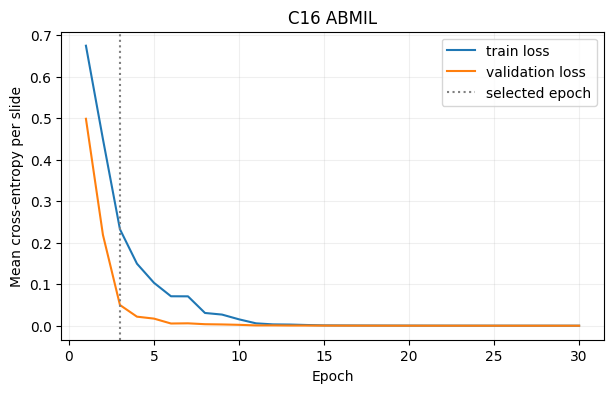

In [15]:
# Plot learning curves.
epochs = [x['epoch'] for x in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [x['train_loss'] for x in history], label='train loss')
plt.plot(epochs, [x['val_loss'] for x in history], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Mean cross-entropy per slide')
plt.axvline(best_epoch, color='gray', linestyle=':', label='selected epoch')
plt.title(DATASET + ' ABMIL')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# Step 7 - Final held-out test evaluation

Only now, after the best checkpoint has been chosen from validation performance, load it and evaluate once on the test set.


In [16]:
model.load_state_dict(best_model_state)
if RUN_TRAINING:
    if RUN_HELD_OUT_TEST:
        test_metrics = evaluate(model, criterion, test_loader, device, conf)
        (out / 'test.json').write_text(json.dumps(test_metrics, indent=2))
        print(test_metrics)
    else:
        print('New experiment test evaluation skipped; use validation for debugging.')
else:
    saved_test = load_saved_test(SAVED_RUN)
    checkpoint_hash = hashlib.sha256((SAVED_RUN / 'best_state.pt').read_bytes()).hexdigest()
    assert checkpoint_hash == saved_test['checkpoint_sha256']
    assert saved_test['best_epoch'] == best_epoch
    assert saved_test['test_slide_ids'] == saved_splits['test']
    test_metrics = saved_test['test']
    print('Recorded held-out evaluation (not rerun):', TEST_RECORD.name)
    print('Validation-selected epoch:', best_epoch)
    print({key: round(value, 4) for key, value in test_metrics.items()})

Recorded held-out evaluation (not rerun): metrics.json
Validation-selected epoch: 3
{'auc': 0.9224, 'acc': 88.3721, 'f1': 0.8714, 'loss': 0.27}


# Step 8 -  Inspect Attention on One Slide

Attention is useful for understanding which instances contribute strongly to the learned bag representation, but attention weights should not automatically be interpreted as causal explanations.


In [17]:
one_batch = mil_collate_fn([val_data[0]])
model.eval()
with torch.no_grad():
    logits, attention = model(
        one_batch['input'].to(device, dtype=torch.float32),
        return_attention=True,
    )

print('Slide:', one_batch['slide_id'][0])
print('Predicted class:', int(logits.argmax(dim=1)[0]))
print('Attention shape:', tuple(attention.shape))
print('Attention sum for first slide:', float(attention[0].sum()))


Slide: tumor_084
Predicted class: 1
Attention shape: (1, 1, 8432)
Attention sum for first slide: 1.0000004768371582


## Visualize Attention on Whole-Slide Images (WSIs)

The required source files have been downloaded and hash-checked. To reproduce on a new machine:

1. Visit the [ECE1512-WSI-Feature dataset on Hugging Face](https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature)

2. Download the original WSIs `test_067.tif` and `test_068.tif` and the corresponding tumor annotation file `test_068.xml`.

3. Create a folder named `slide/` under your project directory and place the downloaded files in this folder.

Run this cell after loading the selected checkpoint, with `DATASET = 'C16'`. It restores `best_model_state` and plots the two slides in `PROJECT_DIR/slide`:

- **test_068 (tumor):** attention overlay and green contours from `test_068.xml`, including a zoom of the annotated region.
- **test_067 (normal):** attention overlay without annotation contours, including a zoom around the highest-attention patch.

The blue rectangle marks the zoom shown on the right. Colors show **attention percentiles within each slide**, not patch tumor probabilities; areas without extracted patches stay transparent. The displayed `P(tumor)` is the model's slide-level prediction.

HDF5 patch coordinates and XML contour coordinates are assumed to be expressed in level-0 `(x, y)`  coordinates; patch coordinates are treated as top-left corners. The function parameter `patch_size_level0=512` is an editable **assumption** for the patch footprint because these HDF5 files do not store patch-size metadata. Match it to the feature extractor's patch size for an exact footprint. All visualization functions are in `wsi_visualization.py`; the cell below only calls `visualize_wsi_attention`.

[OpenSlide Python](https://openslide.org/api/python/) reads a thumbnail and a pyramid-level crop rather than loading the full-resolution WSI into memory. If dependencies are missing, run `%pip install openslide-python openslide-bin` and restart the kernel if needed. Raw per-patch attention and coordinates are retained in `attention_visualizations`.


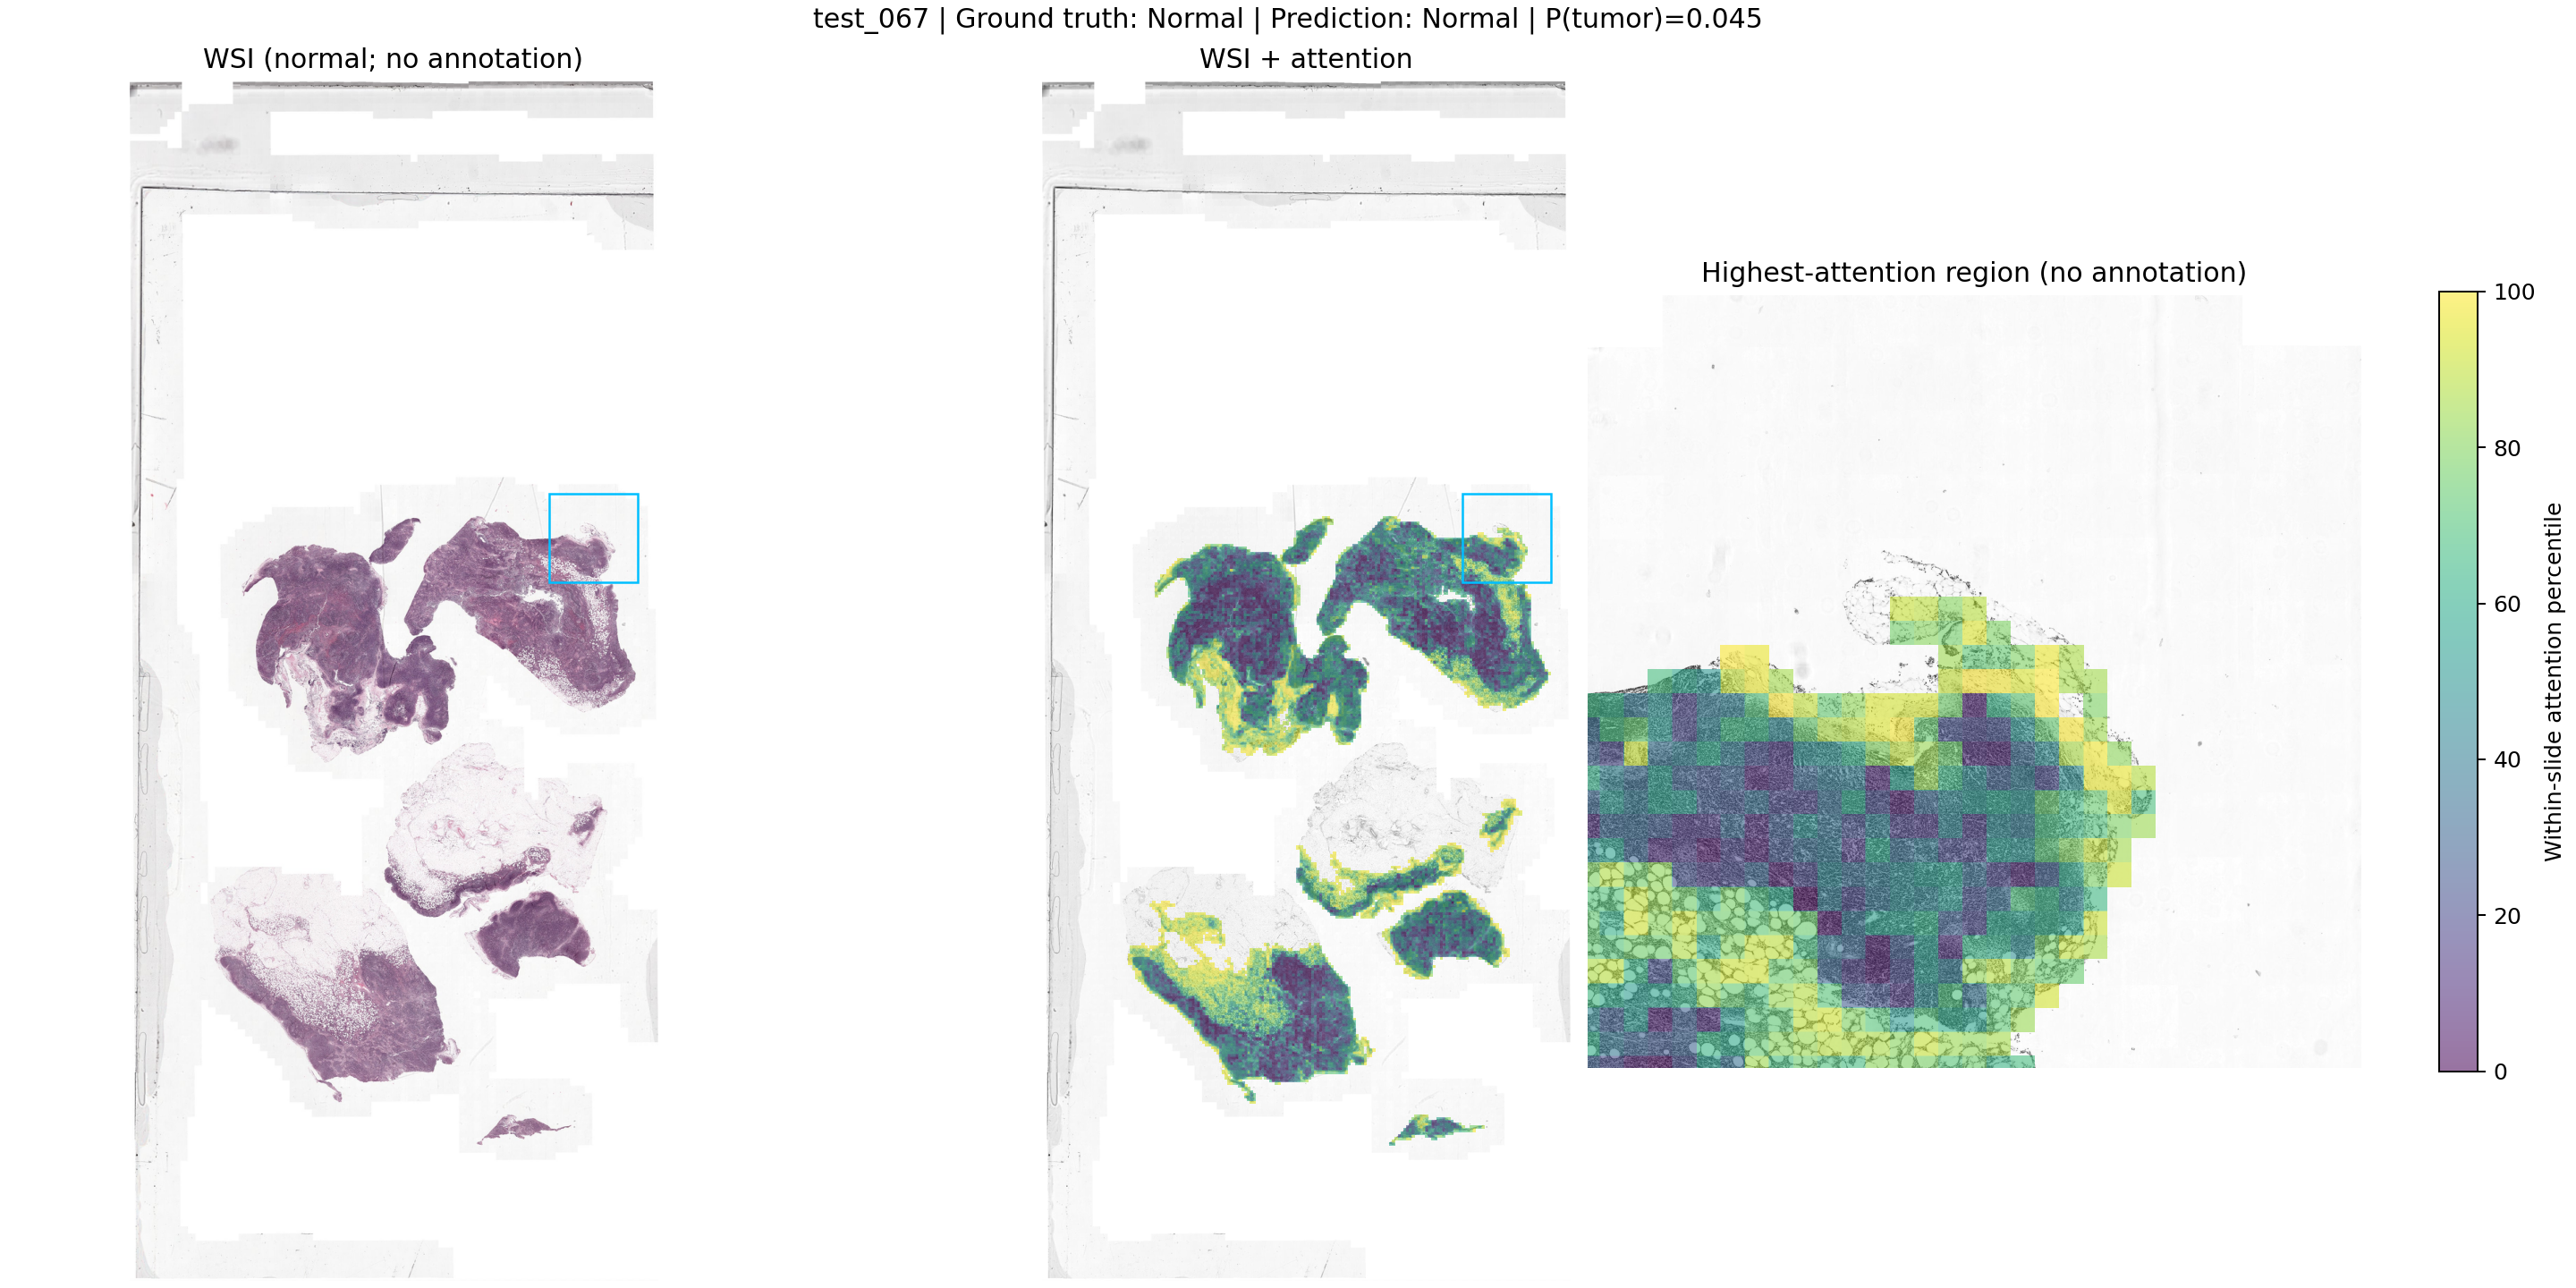

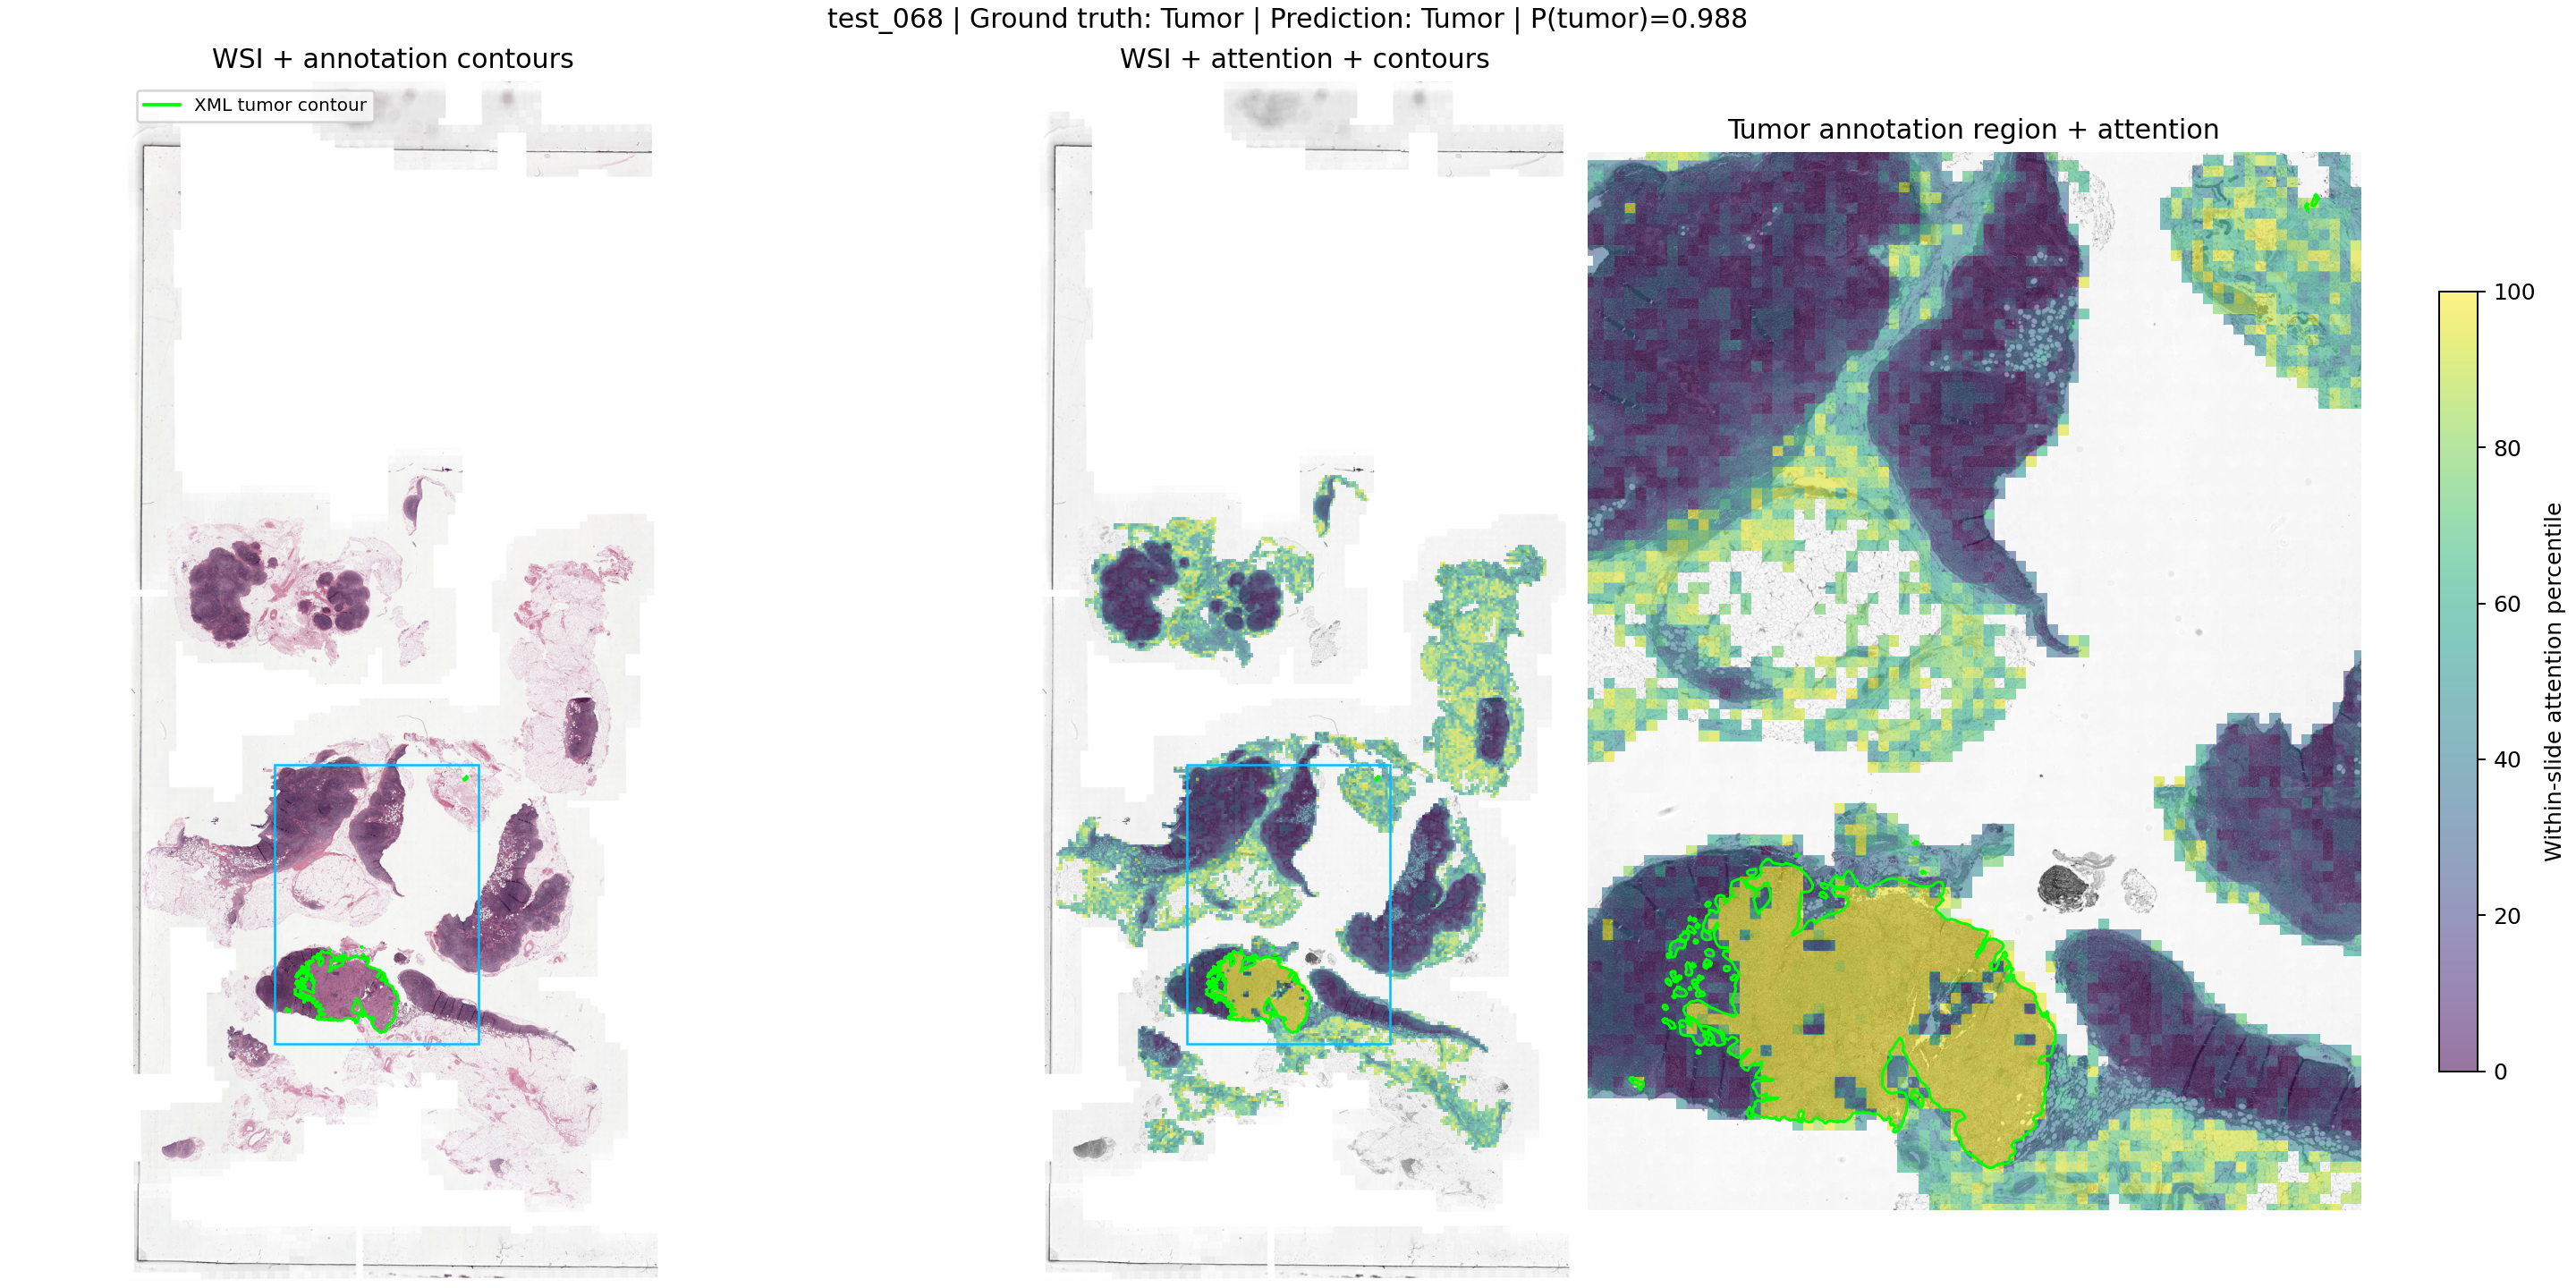

In [18]:
from IPython.display import Image
if DATASET == 'C16' and RUN_WSI_FIGURES and not RUN_TRAINING:
    attention_visualizations = visualize_wsi_attention(
        model, conf, PROJECT_DIR, best_model_state,
        output_dir=PROJECT_DIR / 'results/C16_attention_reproduced')
elif DATASET == 'C16':
    for slide in ('test_067', 'test_068'):
        display(Image(filename=str(PROJECT_DIR / f'results/C16_attention/{slide}_attention.png')))
else:
    print('Saved whole-slide attention examples are from the selected C16 checkpoint.')

## Full baseline comparison
The following table and curves come from the three full runs, independently of the dataset selected above. Test results were computed from validation-selected checkpoints. Accuracy is a percentage; AUC is macro one-vs-rest and F1 is macro at argmax predictions. Each slide has equal weight in loss. These are single-seed results without confidence intervals.

,Dataset,Train/val/test,Epoch,Test accuracy (%),Test macro AUC,Test macro F1,Test loss
0,C16,242/27/129,3,88.3721,0.9224,0.8714,0.2700
1,C17,269/30/200,21,78.5000,0.8226,0.5520,0.7969
2,BRACS,389/62/86,3,46.5116,0.7855,0.3716,1.4110


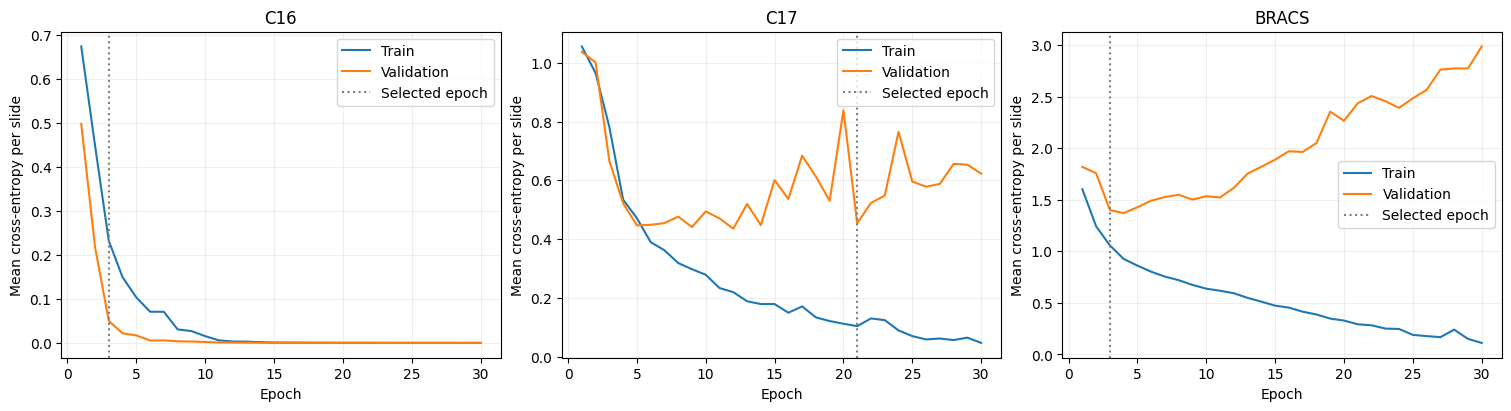

In [19]:
rows = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
for ax, (dataset, run_name) in zip(axes, RUNS.items()):
    folder = PROJECT_DIR / 'results' / run_name
    hist = json.loads((folder / 'history.json').read_text())
    summary = json.loads((folder / 'summary.json').read_text())
    record = load_saved_test(folder)
    splits = json.loads((folder / 'splits.json').read_text())
    assert len(hist) == 30 and record['best_epoch'] == summary['best_epoch']
    assert hashlib.sha256((folder / 'best_state.pt').read_bytes()).hexdigest() == record['checkpoint_sha256']
    assert record['test_slide_ids'] == splits['test']
    rows.append({'Dataset': dataset, 'Train/val/test': '/'.join(str(len(splits[k])) for k in ('train','val','test')),
                 'Epoch': summary['best_epoch'], 'Test accuracy (%)': record['test']['acc'],
                 'Test macro AUC': record['test']['auc'], 'Test macro F1': record['test']['f1'],
                 'Test loss': record['test']['loss']})
    ax.plot([r['epoch'] for r in hist], [r['train_loss'] for r in hist], label='Train')
    ax.plot([r['epoch'] for r in hist], [r['val_loss'] for r in hist], label='Validation')
    ax.axvline(summary['best_epoch'], color='gray', linestyle=':', label='Selected epoch')
    ax.set(title=dataset, xlabel='Epoch', ylabel='Mean cross-entropy per slide')
    ax.grid(alpha=.2)
    ax.legend()
display(pd.DataFrame(rows).round(4))
plt.show()

### Interpretation and limits
C16 reaches perfect validation AUROC and macro F1 at epoch 3 on 27 validation slides, but its held-out accuracy is 88.37% and AUROC 0.9224 on 129 slides. C17 selects epoch 21, with held-out accuracy 78.50%, AUROC 0.8226 and macro F1 0.5520. Its frequent classes dominate accuracy; macro and per-class metrics expose minority-class errors. BRACS selects epoch 3, with accuracy 46.51%, AUROC 0.7855 and macro F1 0.3716. Decreasing training loss and rising later validation loss indicate overfitting. Selection maximizes validation AUROC plus macro F1, not minimum loss.

The datasets have different labels and populations, so their accuracies do not directly rank task difficulty. C17 training and validation share 27 patients; test patients are separate. Each configuration has one seed. Primary baselines were trained in George's Windows environment; full extension and control runs were trained on Aaron's Mac. Source environments, partitions and checkpoint hashes are preserved. The earlier Mac C17 baseline achieved 73.00% accuracy, AUROC 0.8325 and macro F1 0.5426 at epoch 19; this difference limits causal attribution across environments. Earlier debug-test exposure is disclosed in the report.

The two C16 whole-slide figures are qualitative examples. Attention colors are relative percentiles, not patch tumour probabilities. The assumed 512-pixel level-zero footprint is not verified extraction metadata. The baseline method is Ilse, Tomczak and Welling, *Attention-based Deep Multiple Instance Learning*, ICML/PMLR 80, 2127–2136, 2018, https://proceedings.mlr.press/v80/ilse18a.html.


## Pooling extension and controls
The implemented proposal uses the total-variation change in class probabilities after suppressing the highest-scoring 10% of patch equivalents to set a detached, slide-specific attention–mean mixture. `research/PROTOCOL.md` defines the method and `research/FINAL_PROTOCOL_20261102.md` fixes the full comparison. Normalized attention entropy regularization is the second, distinct proposal; it is not implemented.

The following table reads the final 30-epoch held-out comparison. It performs no training or held-out model inference. Fixed 50/50 controls reuse the October 28 records; fragility and pure mean use the November 2 full runs. Fixed-mixture per-slide probabilities were not retained. The report interprets the measured differences and their limitations.

,dataset,method,best_epoch,test_slides,Macro AUROC,Accuracy (%),Macro F1,Cross entropy
0,C16,ABMIL,3,129,0.9224,88.3721,0.8714,0.2700
1,C16,Fixed 50/50,3,129,0.9128,90.6977,0.8986,0.2738
2,C16,Mean,16,129,0.6107,65.8915,0.5831,0.6551
3,C16,Fragility,12,129,0.9069,86.0465,0.8480,0.3799
4,C17,ABMIL,21,200,0.8226,78.5000,0.5520,0.7969
5,C17,Fixed 50/50,7,200,0.8640,81.0000,0.4922,0.5054
6,C17,Mean,2,200,0.7045,60.5000,0.1885,0.9928
7,C17,Fragility,19,200,0.8428,78.5000,0.5218,0.6753
8,BRACS,ABMIL,3,86,0.7855,46.5116,0.3716,1.4110
9,BRACS,Fixed 50/50,12,86,0.7860,44.1860,0.3671,1.4786


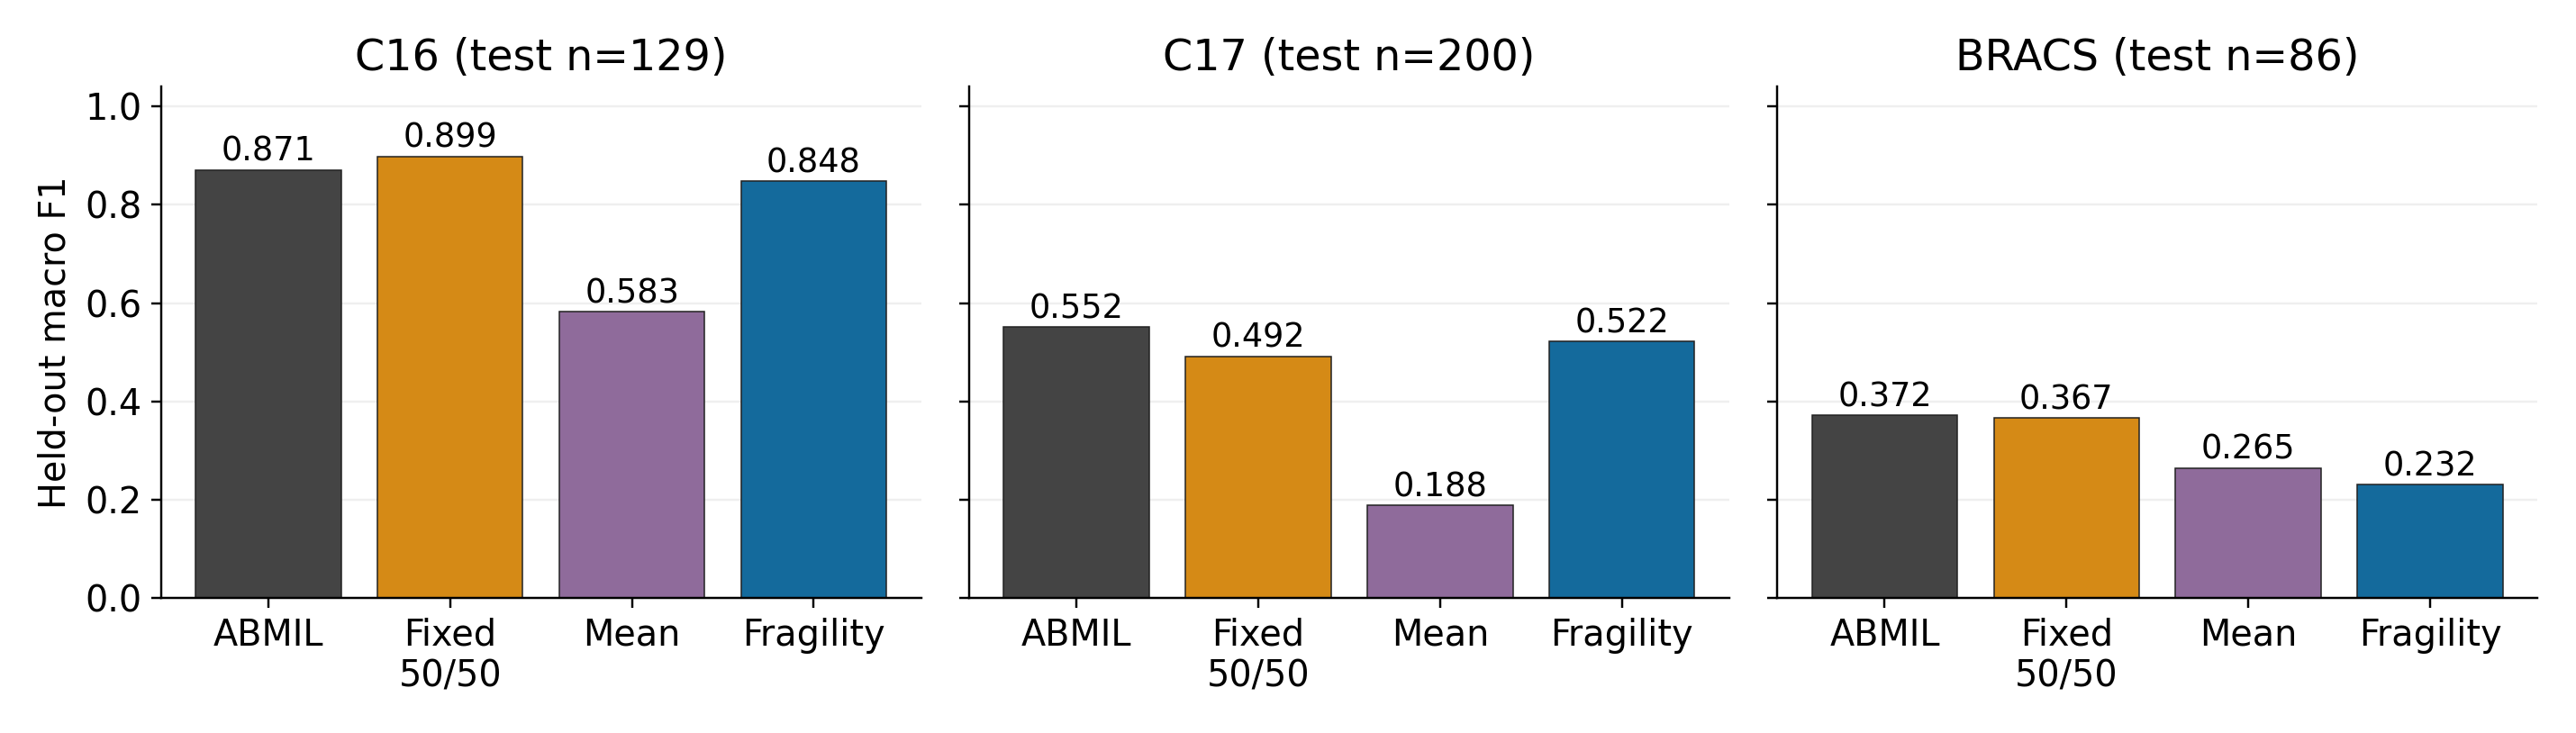

In [20]:
comparison_dir = PROJECT_DIR / 'results/full_comparison_20261102'
comparison = pd.read_csv(comparison_dir / 'comparison.csv')
display(comparison.rename(columns={'acc': 'Accuracy (%)', 'auc': 'Macro AUROC',
                                   'f1': 'Macro F1', 'loss': 'Cross entropy'}).round(4))
display(Image(filename=str(comparison_dir / 'pooling_controls.png')))
